In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

DATA_DIR = "c:/Users/lava0/Desktop/한국외대/사회과학과 데이터 사이언스"
PAIRS = f"{DATA_DIR}/MicroLens-100k_pairs.csv"
LIKES = f"{DATA_DIR}/MicroLens-100k_likes_and_views.txt"
TAGS = f"{DATA_DIR}/tags_to_summary.csv"

likes = pd.read_csv(
    LIKES,
    sep="\t",
    header=None,
    names=["item", "likes", "views"]
)

tags = pd.read_csv(TAGS, header=None, names=["item", "category"])

df = pd.merge(
    likes,
    tags,
    on="item",
    how="inner"
)

df = df[["item", "likes", "views", "category"]]
df.head()



,item,likes,views,category
0,1,12000,414000,Anime
1,2,20000,1301143,Delicacy
2,3,132000,4108000,Daily Sharing
3,4,70000,798000,Game
4,5,31000,3078226,Film and Television Works


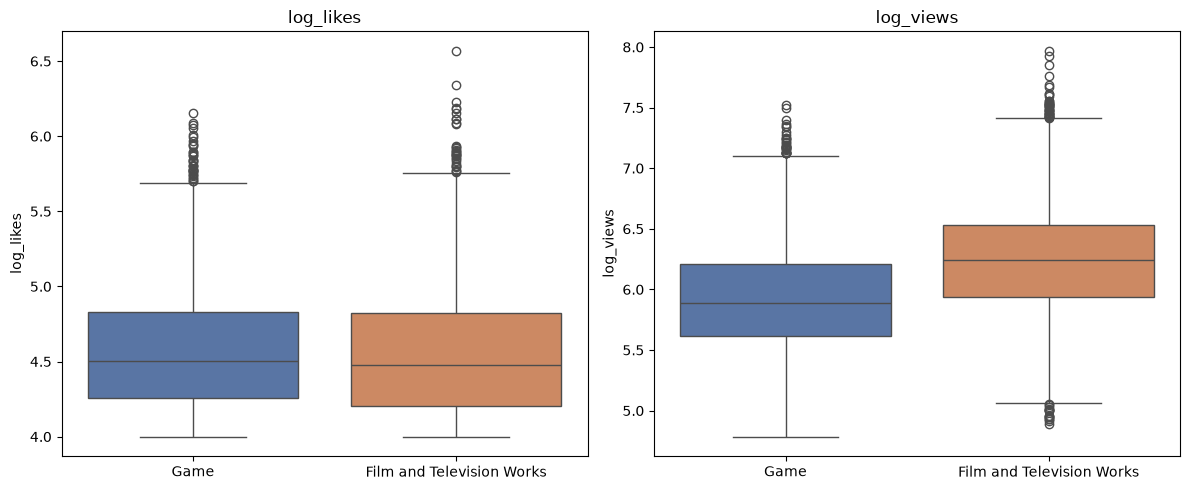

In [28]:
df_box = df[
    df["category"].isin(["Game", "Film and Television Works"])
].copy()

# 로그 변환
df_box["log_likes"] = np.log10(df_box["likes"])
df_box["log_views"] = np.log10(df_box["views"])

# 색상
colors = ["#4C72B0", "#DD8452"]

# 하나의 Figure에 두 그래프
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=df_box,
    x="category",
    y="log_likes",
    hue="category",
    palette=colors,
    legend=False,
    ax=axes[0]
)

axes[0].set_title("log_likes")
axes[0].set_xlabel("")
axes[0].set_ylabel("log_likes")

sns.boxplot(
    data=df_box,
    x="category",
    y="log_views",
    hue="category",
    palette=colors,
    legend=False,
    ax=axes[1]
)

axes[1].set_title("log_views")
axes[1].set_xlabel("")
axes[1].set_ylabel("log_views")

plt.tight_layout()
plt.show()

In [31]:
A, B = "Game", "Film and Television Works"

two = df[df["category"].isin([A, B])].copy()

two["log_likes"] = np.log10(two["likes"])
two["log_views"] = np.log10(two["views"])

display(
    two.groupby("category")[["likes", "views"]]
       .mean()
)

,likes,views
category,,
Film and Television Works,65100.766703,3.115118e+06
Game,61876.022057,1.438307e+06


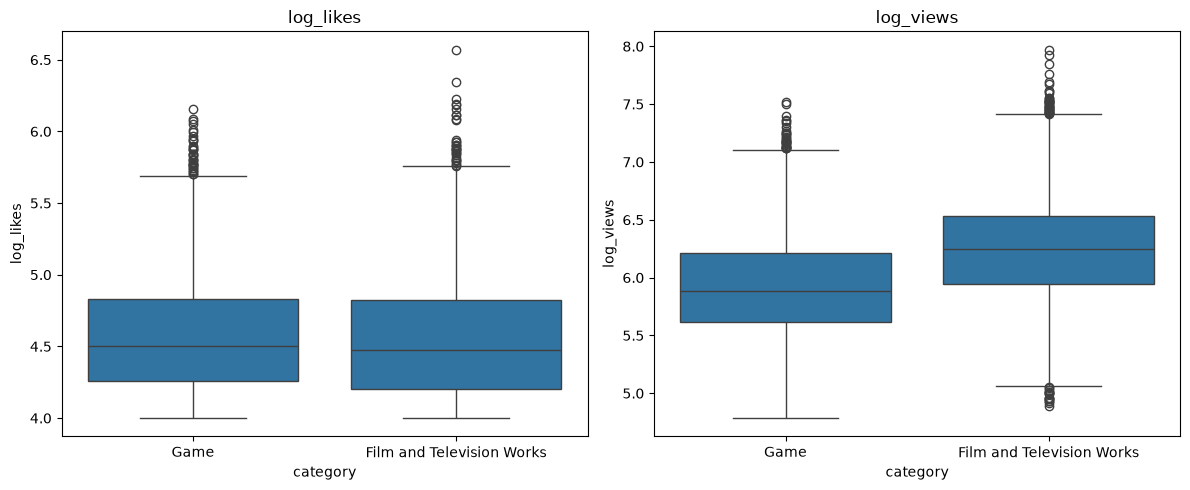

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=two,
    x="category",
    y="log_likes",
    ax=axes[0]
)

sns.boxplot(
    data=two,
    x="category",
    y="log_views",
    ax=axes[1]
)

axes[0].set_title("log_likes")
axes[1].set_title("log_views")

plt.tight_layout()
plt.show()

In [51]:
game = two[two["category"] == A]
film = two[two["category"] == B]

t_likes, p_likes = stats.ttest_ind(
    game["log_likes"],
    film["log_likes"],
    equal_var=False
)

t_views, p_views = stats.ttest_ind(
    game["log_views"],
    film["log_views"],
    equal_var=False
)

print("Likes:", "t =", t_likes, "p =", format(p_likes, "f"))
print("Views:", "t =", t_views, "p =", format(p_views, "f"))

Likes: t = 1.8197628573059808 p = 0.068827
Views: t = -35.484008112695925 p = 0.000000


In [30]:
alpha = 0.05

print("\n=== 결과 해석 ===")

if likes_p < alpha:
    print("Likes: p < 0.05 이므로 Game과 Film and Television Works의 평균 likes 차이는 통계적으로 유의하다.")
else:
    print("Likes: p >= 0.05 이므로 Game과 Film and Television Works의 평균 likes 차이는 통계적으로 유의하지 않다.")

if views_p < alpha:
    print("Views: p < 0.05 이므로 Game과 Film and Television Works의 평균 views 차이는 통계적으로 유의하다.")
else:
    print("Views: p >= 0.05 이므로 Game과 Film and Television Works의 평균 views 차이는 통계적으로 유의하지 않다.")


=== 결과 해석 ===
Likes: p >= 0.05 이므로 Game과 Film and Television Works의 평균 likes 차이는 통계적으로 유의하지 않다.
Views: p < 0.05 이므로 Game과 Film and Television Works의 평균 views 차이는 통계적으로 유의하다.


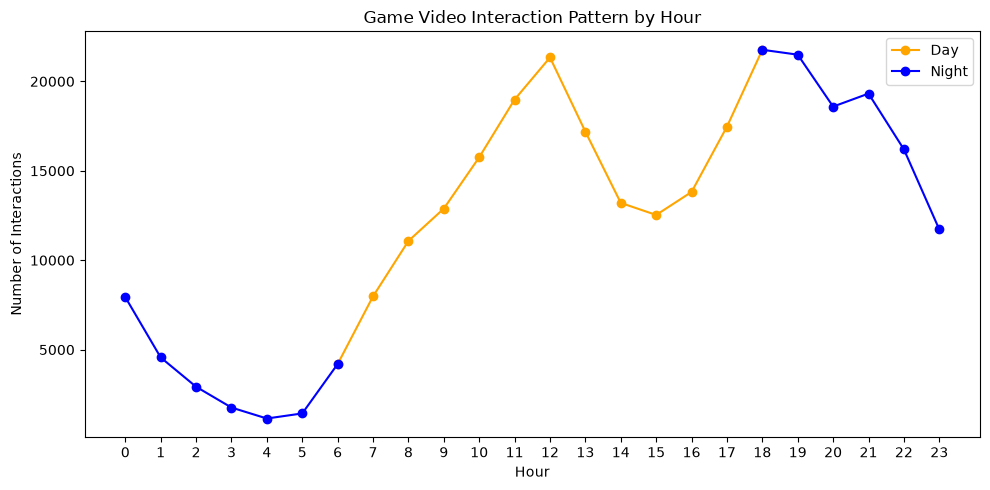

In [62]:
# Game 영상의 item만 추출
game_items = df.loc[
    df["category"] == "Game", "item"
]

# Game 영상에 대한 상호작용만 추출
game = pairs[
    pairs["item"].isin(game_items)
].copy()

# timestamp: 밀리초 → UTC+8 시간
game["datetime"] = pd.to_datetime(
    game["timestamp"],
    unit="ms",
    utc=True
).dt.tz_convert("Asia/Shanghai")

# 시간 추출
game["hour"] = game["datetime"].dt.hour

# 낮: 06~18시, 밤: 18~06시
game["period"] = np.where(
    (game["hour"] >= 6) & (game["hour"] < 18),
    "Day",
    "Night"
)

game.head()

hourly_counts = (
    game.groupby("hour")
    .size()
    .reindex(range(24), fill_value=0)
)

plt.figure(figsize=(10, 5))

# 낮: 06~18시
plt.plot(
    range(6, 19),
    hourly_counts.loc[6:18],
    marker="o",
    color="orange",
    label="Day"
)

# 밤: 18~06시
# 18~23시
plt.plot(
    range(18, 24),
    hourly_counts.loc[18:23],
    marker="o",
    color="blue",
    label="Night"
)

# 00~06시
plt.plot(
    range(0, 7),
    hourly_counts.loc[0:6],
    marker="o",
    color="blue"
)

plt.xticks(range(24))
plt.xlabel("Hour")
plt.ylabel("Number of Interactions")
plt.title("Game Video Interaction Pattern by Hour")
plt.legend()

plt.tight_layout()
plt.show()

In [68]:
from scipy.stats import ttest_ind

# 낮과 밤의 상호작용 수
day = game.loc[game["period"] == "Day"].groupby("hour").size()
night = game.loc[game["period"] == "Night"].groupby("hour").size()

# 낮/밤 각각의 시간별 상호작용 수를 비교
t_stat, p_value = ttest_ind(
    day,
    night,
    equal_var=False
)

print("Day 평균 상호작용 수:", day.mean())
print("Night 평균 상호작용 수:", night.mean())
print("t-statistic:", t_stat)
print("p-value:", p_value)

# 유의성 판단
alpha = 0.05

if p_value < alpha:
    print("결론: 낮과 밤의 상호작용 수는 통계적으로 유의하게 다르다.")
else:
    print("결론: 낮과 밤의 상호작용 수는 통계적으로 유의한 차이가 없다.")

Day 평균 상호작용 수: 13869.583333333334
Night 평균 상호작용 수: 10738.25
t-statistic: 1.1275407487831512
p-value: 0.27478944943928635
결론: 낮과 밤의 상호작용 수는 통계적으로 유의한 차이가 없다.
